In [1]:
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "mrpc"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 3668
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'Amrozi accused his brother , whom he called " the witness " , of deliberately distorting his evidence .',
 'sentence2': 'Referring to him as only " the witness " , Amrozi accused his brother of deliberately distorting his evidence .',
 'label': 1,
 'idx': 0}

In [10]:
raw_train_dataset[5]['sentence1'], raw_train_dataset[5]['sentence2']

('Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .',
 "With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .")

In [11]:
raw_train_dataset[5]['label']

1

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['not_equivalent', 'equivalent']),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 100]),
 'token_type_ids': torch.Size([32, 100]),
 'attention_mask': torch.Size([32, 100])}

# 4. Loading model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
len(model.bert.encoder.layer)

12

In [25]:
model.bert.encoder.layer = model.bert.encoder.layer[:7]

In [26]:
len(model.bert.encoder.layer)

7

In [31]:
from train_eval_func import eval_loop

In [32]:
eval_loop(model, eval_dataloader, task_name, device)

({'accuracy': 0.33507246376811595, 'f1': 0.0}, 1.0916479031244914)

In [27]:
teacher_model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [28]:
teacher_model.set_use_module_grafting(False)
teacher_model.set_use_scc_status(False)

In [29]:
outputs = teacher_model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(0.6582, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [30]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)
teacher_model.to(device)

device

device(type='cuda')

### Load Trained Weights

In [33]:
load_path = './weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
teacher_model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [34]:
eval_loop(teacher_model, val_dataloader, task_name, device)[0]

{'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624}

# 5. Learning Rate and Leanring Scheduler Setup

In [35]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=3e-5)

In [36]:
from train_eval_func import set_lr_scheduler

num_epochs = 10
num_training_steps = num_epochs * len(train_dataloader)

lr_scheduler = set_lr_scheduler(
    optimizer          = optimizer,
    num_training_steps = num_training_steps
)

print(num_training_steps)

1150


In [37]:
patience=3
save_path=f'./weights/bert-7l-kd-{task_name}.pt'

# 6. Training

In [38]:
from train_eval_func import train

In [39]:
train_stats = train(
    model,
    train_dataloader,
    val_dataloader,
    task_name,
    device,
    num_epochs=num_epochs,
    lr=lr_scheduler,
    patience=patience,
    use_early_stopping=True,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    save_path=save_path,
    display_epoch_iter=True,
    teacher_model=teacher_model
)

Training:   0%|          | 0/1150 [00:00<?, ?it/s]

Knowledge distillation used!


/home/abhinavl/work/Layer_Graft/layer-grafting-publication/glue_fine_tune/../train_eval_func.py:240: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  total_loss += float(loss)
Training:  10%|█         | 115/1150 [00:26<03:36,  4.77it/s]

✓ Saved checkpoint (best loss: 0.6976)

<----------------- Epoch 1 ----------------->
Loss: 2.58, Training Metrics:
  accuracy: 0.7020
  f1: 0.8081
Validation Loss: 0.7, Validation Metrics:
  accuracy: 0.7941
  f1: 0.8650
Elapsed Time: 27.6431 sec


Training:  20%|██        | 230/1150 [01:02<03:13,  4.76it/s]

✓ Saved checkpoint (best loss: 0.8534)

<----------------- Epoch 2 ----------------->
Loss: 1.65, Training Metrics:
  accuracy: 0.8242
  f1: 0.8738
Validation Loss: 0.85, Validation Metrics:
  accuracy: 0.8186
  f1: 0.8795
Elapsed Time: 27.5157 sec


... (2 outputs left out)

Training:  40%|████      | 460/1150 [02:05<02:24,  4.76it/s]


<----------------- Epoch 4 ----------------->
Loss: 0.4, Training Metrics:
  accuracy: 0.9569
  f1: 0.9681
Validation Loss: 1.02, Validation Metrics:
  accuracy: 0.8015
  f1: 0.8571
Elapsed Time: 27.5715 sec


Training:  50%|█████     | 575/1150 [02:33<02:03,  4.65it/s]


<----------------- Epoch 5 ----------------->
Loss: 0.25, Training Metrics:
  accuracy: 0.9722
  f1: 0.9794
Validation Loss: 1.22, Validation Metrics:
  accuracy: 0.8162
  f1: 0.8764
Elapsed Time: 27.4734 sec
>>>>> Early stopping callback <<<<<

Total Training Time: 154.76 sec
Chosen Primary Metric: f1
Best Metric Run: 0.8795


### Plotting Loss

In [40]:
from train_eval_func import plotLoss, plotAccuracy

Training:  50%|█████     | 575/1150 [05:25<05:25,  1.77it/s]


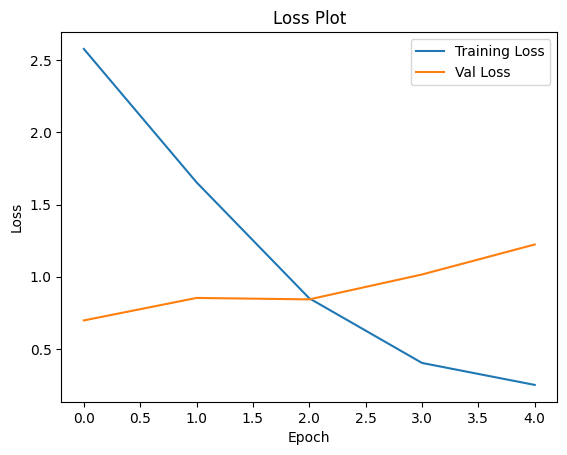

In [41]:
plotLoss(train_stats['train_losses'], train_stats['val_losses'], title="Loss Plot")

### Plotting Accuracy

In [42]:
def getMetricList(train_stats, metric_name='accuracy'):
    train_values = [m[metric_name] for m in train_stats['train_metrics_history']]
    val_values = [m[metric_name] for m in train_stats['val_metrics_history']]

    return train_values, val_values

In [43]:
train_values, val_values = getMetricList(train_stats)

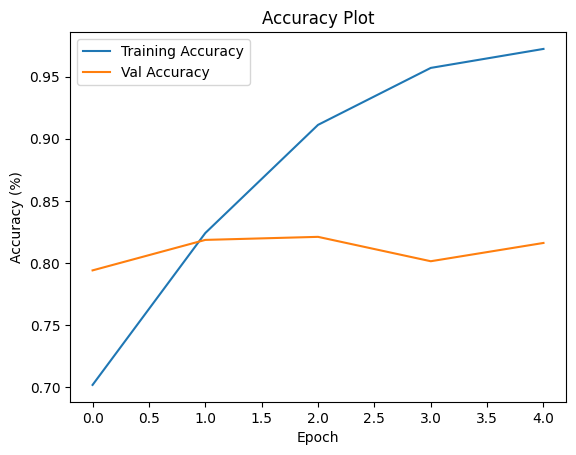

In [44]:
plotAccuracy(train_values, val_values, title="Accuracy Plot")

In [45]:
train_values, val_values = getMetricList(train_stats, 'f1')

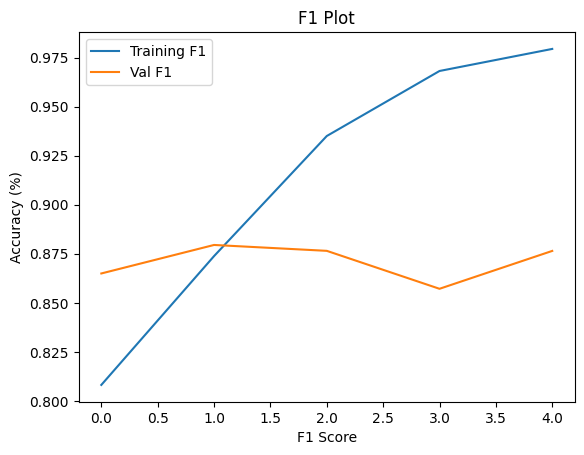

In [46]:
plotAccuracy(train_values, val_values, legend=["Training F1", "Val F1"], title="F1 Plot", xlabel="F1 Score")

# 7. Evaluation

In [47]:
best_weight = torch.load(save_path)

In [48]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [49]:
eval_loop(model, eval_dataloader, task_name, device)[0]

{'accuracy': 0.7866666666666666, 'f1': 0.8553459119496856}

In [50]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.8186274509803921, 'f1': 0.8794788273615635}

In [51]:
best_weight['epoch']

2